<a href="https://colab.research.google.com/github/vanixcore/neurotwin/blob/main/NeuroTwin_AI_Real_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NeuroTwin AI - Real-data Edition (learning project)

A small learning prototype inspired by the idea of a "digital brain" foundation model. It is not the Stanford model, has no affiliation with it, and is not a medical or diagnostic tool.

**Data:** public fMRI data (OpenNeuro ds000228, movie-watching task), parcellated to 100 regions (Schaefer atlas), 128 subjects after a pre-specified head-motion exclusion rule. See dataset_card.md.

**Pipeline:** parcellated fMRI -> preprocessing -> Transformer encoder -> self-supervised masked pretraining -> future-activity forecasting -> evaluation against baselines -> uncertainty.

**Research question:** does masked-reconstruction pretraining improve forecasting of held-out subjects on a small real dataset, and does the effect change with the number of training subjects? See research_plan.md.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJ = '/content/drive/MyDrive/neurotwin'
os.makedirs(f'{PROJ}/checkpoints', exist_ok=True)
os.makedirs(f'{PROJ}/data', exist_ok=True)

!nvidia-smi | head -n 12

Mounted at /content/drive
Tue Nov 10 11:43:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

## Cell 1 - Imports, seed and device
**What this cell does:** imports all libraries, fixes random seeds for reproducibility, and picks GPU if available (otherwise CPU).

In [5]:
import os, json, math, random
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, detrend
from sklearn.decomposition import PCA

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.14.1+cu130 | Device: cuda


## Cell 2 - Central configuration
**What this cell does:** defines every hyper-parameter in one dataclass (data size, window lengths, model size, training epochs) so experiments are easy to change and reproduce.

In [6]:
@dataclass
class Cfg:
    # data
    n_subjects: int = 60
    n_regions: int = 16        # number of brain regions (ROIs)
    n_latents: int = 4         # hidden brain "networks" generating the signals
    T: int = 600               # time points per subject (1 sample = 1 TR = 2 second)
    # windowing
    ctx: int = 64              # context length the model sees
    horizon: int = 16          # how many future steps we predict
    stride: int = 8
    # model
    d_model: int = 64
    heads: int = 4
    layers: int = 2
    dropout: float = 0.1
    # training
    batch: int = 64
    pre_epochs: int = 15       # self-supervised pretraining epochs
    ft_epochs: int = 20        # forecasting fine-tuning epochs
    lr: float = 1e-3
    mask_ratio: float = 0.3
    patch: int = 4             # masked patch size (time steps)

cfg = Cfg(n_subjects=128, n_regions=100, T=168, horizon=10)
print(cfg)

Cfg(n_subjects=128, n_regions=100, n_latents=4, T=168, ctx=64, horizon=10, stride=8, d_model=64, heads=4, layers=2, dropout=0.1, batch=64, pre_epochs=15, ft_epochs=20, lr=0.001, mask_ratio=0.3, patch=4)


## Cell 3 - Load real parcellated fMRI data
**What this cell does:** loads the saved array of shape (subjects, time, regions) produced in 01_data_prep.ipynb, the participant table (child/adult label), and the fixed subject-wise splits (splits.json). Subjects with mean framewise displacement above 0.5 mm were already excluded before this step.

In [7]:
raw = np.load(f'{PROJ}/data/X_kept.npy')                  # (128, 168, 100)
pk = pd.read_csv(f'{PROJ}/data/phenotypic_kept.csv')
splits = json.load(open(f'{PROJ}/data/splits.json'))
assert list(pk['participant_id']) == json.load(open(f'{PROJ}/data/subject_ids_kept.json'))
row_of = {sid: i for i, sid in enumerate(pk['participant_id'])}
groups = (pk['Child_Adult'] == 'adult').astype(int).values        # 0 = child, 1 = adult
R, T = raw.shape[2], raw.shape[1]
roi_names = [f"ROI_{i:03d}" for i in range(R)]
assert raw.shape == (cfg.n_subjects, cfg.T, cfg.n_regions)
print("Real data shape (subjects, time, regions):", raw.shape)

Real data shape (subjects, time, regions): (128, 168, 100)


## Cell 4 - Preprocessing (detrend, z-score)
**What this cell does:** removes linear drift and z-scores every region per subject so all regions are on the same scale. No band-pass filter is applied, because a zero-phase filter would use future samples to compute past values (look-ahead). Normalisation uses each subject's whole scan, so absolute scores may be slightly optimistic; this affects all models and baselines equally.

In [8]:
def preprocess(x):
    """x: (time, regions) -> detrended, z-scored (time, regions). No band-pass (see notes)."""
    x = detrend(x, axis=0)
    x = (x - x.mean(0, keepdims=True)) / (x.std(0, keepdims=True) + 1e-8)
    return x.astype(np.float32)

clean = np.stack([preprocess(s) for s in raw])
print("Clean data shape:", clean.shape, "| mean ~", clean.mean().round(4), "| std ~", clean.std().round(4))

Clean data shape: (128, 168, 100) | mean ~ -0.0 | std ~ 1.0


## Cell 5 - Subject-wise splits and sliding windows
**What this cell does:** reads the fixed train/validation/calibration/test subject splits from splits.json (stratified by child/adult, never regenerated after seeing results). It cuts each subject's time series into overlapping windows of `ctx + horizon` steps: the first `ctx` are input, the last `horizon` are the forecast target. It checks that no subject appears in more than one split.

In [9]:
split = {k: np.array([row_of[s] for s in splits[k]]) for k in ['train', 'val', 'cal', 'test']}

def make_windows(subj_rows):
    L = cfg.ctx + cfg.horizon
    wins, sid = [], []
    for s in subj_rows:
        for start in range(0, cfg.T - L + 1, cfg.stride):
            wins.append(clean[s, start:start + L]); sid.append(s)
    return torch.tensor(np.stack(wins)), np.array(sid)

data, win_subj = {}, {}
for name, rows in split.items():
    data[name], win_subj[name] = make_windows(rows)
    print(f"{name:5s}: {len(rows):3d} subjects -> windows {tuple(data[name].shape)}")

names = list(split)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        assert not (set(split[names[i]]) & set(split[names[j]])), f"Leakage: {names[i]} / {names[j]} overlap!"
print("No subject overlap between any splits: OK")

train:  76 subjects -> windows (912, 74, 100)
val  :  16 subjects -> windows (192, 74, 100)
cal  :  16 subjects -> windows (192, 74, 100)
test :  20 subjects -> windows (240, 74, 100)
No subject overlap between any splits: OK


## Cell 6 - functional connectivity
**What this cell does:** plots (1) raw vs preprocessed signal of one region, (2) the region x time activity heatmap of one subject, and (3) the region-to-region correlation matrix (functional connectivity) for that subject.

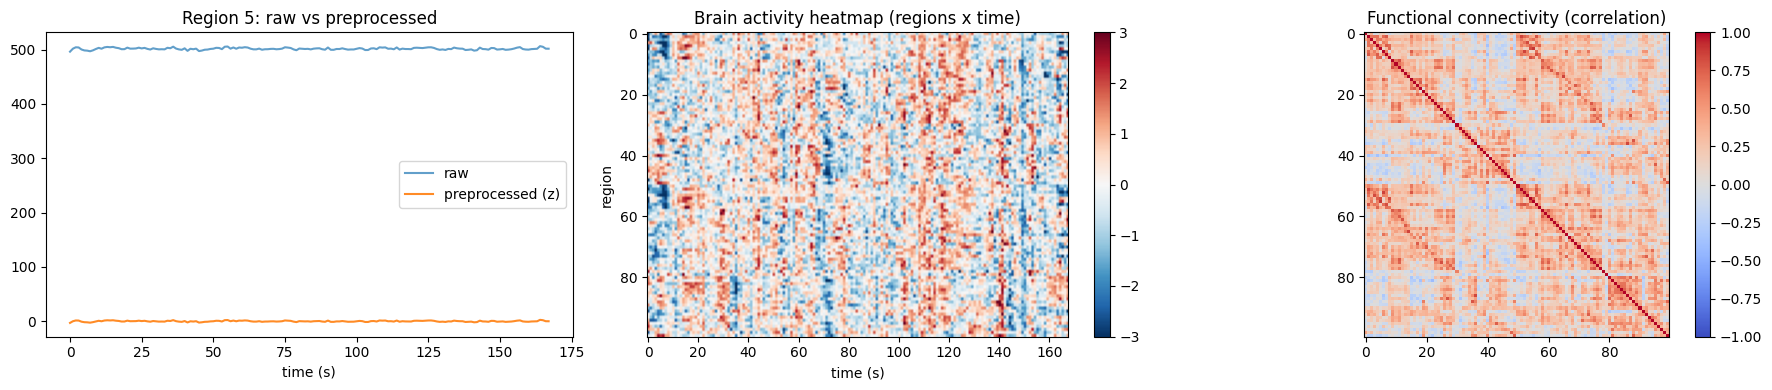

In [10]:
s0 = 0
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(raw[s0, :, 5], label="raw", alpha=0.7)
ax[0].plot(clean[s0, :, 5], label="preprocessed (z)", alpha=0.9)
ax[0].set_title("Region 5: raw vs preprocessed"); ax[0].set_xlabel("time (s)"); ax[0].legend()

im = ax[1].imshow(clean[s0].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
ax[1].set_title("Brain activity heatmap (regions x time)"); ax[1].set_xlabel("time (s)"); ax[1].set_ylabel("region")
plt.colorbar(im, ax=ax[1])

conn = np.corrcoef(clean[s0].T)
im2 = ax[2].imshow(conn, cmap="coolwarm", vmin=-1, vmax=1)
ax[2].set_title("Functional connectivity (correlation)"); plt.colorbar(im2, ax=ax[2])
plt.tight_layout(); plt.show()

## Cell 7 - Brain foundation model (Transformer encoder)
**What this cell does:** defines the model. Each time step (a vector of 100 region values) is projected to a token, positional embeddings are added, and a Transformer encoder models temporal dependencies. Two heads share this encoder: a **reconstruction head** (for masked self-supervised pretraining) and a **forecast head** (predicts the next `horizon` steps for all regions).

In [11]:
class BrainEncoder(nn.Module):
    def __init__(self, c: Cfg):
        super().__init__()
        self.c = c
        self.inp = nn.Linear(c.n_regions, c.d_model)
        self.pos = nn.Parameter(torch.randn(1, c.ctx, c.d_model) * 0.02)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, c.d_model))
        layer = nn.TransformerEncoderLayer(
            d_model=c.d_model, nhead=c.heads, dim_feedforward=c.d_model * 4,
            dropout=c.dropout, batch_first=True, activation="gelu", norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=c.layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(c.d_model)
        self.recon_head = nn.Linear(c.d_model, c.n_regions)
        self.forecast_head = nn.Sequential(
            nn.Linear(c.d_model, c.d_model), nn.GELU(),
            nn.Linear(c.d_model, c.horizon * c.n_regions))

    def encode(self, x, mask=None):
        h = self.inp(x)
        if mask is not None:                      # replace masked time steps by a learned token
            h = torch.where(mask.unsqueeze(-1), self.mask_token.expand_as(h), h)
        return self.norm(self.encoder(h + self.pos))

    def reconstruct(self, x, mask):
        return self.recon_head(self.encode(x, mask))

    def forecast(self, x):
        h = self.encode(x)
        z = h.mean(1) + h[:, -1]                  # global summary + most recent state
        return self.forecast_head(z).view(-1, self.c.horizon, self.c.n_regions)

model = BrainEncoder(cfg).to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Parameters: 186380


## Cell 8 - Self-supervised pretraining (masked reconstruction)
**What this cell does:** trains the encoder WITHOUT any forecasting labels. Random patches of time steps are hidden and the model must reconstruct them from the surrounding context. Loss is computed only on the hidden steps. This is the "foundation model" idea: learn general brain-signal structure first.

In [12]:
def random_patch_mask(B, L, patch, ratio, dev):
    n_patches = L // patch
    m = torch.rand(B, n_patches, device=dev) < ratio
    return m.repeat_interleave(patch, dim=1)       # (B, L) boolean

def batches(x, bs, shuffle=True):
    idx = torch.randperm(len(x)) if shuffle else torch.arange(len(x))
    for i in range(0, len(x), bs):
        yield x[idx[i:i + bs]]

def pretrain(model, epochs):
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=1e-4)
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); tl, n = 0.0, 0
        for xb in batches(data["train"][:, :cfg.ctx], cfg.batch):
            xb = xb.to(device)
            m = random_patch_mask(len(xb), cfg.ctx, cfg.patch, cfg.mask_ratio, device)
            pred = model.reconstruct(xb, m)
            loss = ((pred - xb) ** 2)[m].mean()    # loss only on masked positions
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(xb); n += len(xb)
        model.eval(); vl, vn = 0.0, 0
        with torch.no_grad():
            for xb in batches(data["val"][:, :cfg.ctx], 256, shuffle=False):
                xb = xb.to(device)
                m = random_patch_mask(len(xb), cfg.ctx, cfg.patch, cfg.mask_ratio, device)
                vl += ((model.reconstruct(xb, m) - xb) ** 2)[m].mean().item() * len(xb); vn += len(xb)
        hist["train"].append(tl / n); hist["val"].append(vl / vn)
        print(f"[pretrain] epoch {ep+1:2d}/{epochs}  train={hist['train'][-1]:.4f}  val={hist['val'][-1]:.4f}")
    return hist

pre_hist = pretrain(model, cfg.pre_epochs)

[pretrain] epoch  1/15  train=1.0330  val=0.9677
[pretrain] epoch  2/15  train=0.9783  val=0.9694
[pretrain] epoch  3/15  train=0.9628  val=0.9654
[pretrain] epoch  4/15  train=0.9598  val=0.9511
[pretrain] epoch  5/15  train=0.9544  val=0.9656
[pretrain] epoch  6/15  train=0.9669  val=0.9592
[pretrain] epoch  7/15  train=0.9533  val=0.9583
[pretrain] epoch  8/15  train=0.9529  val=0.9618
[pretrain] epoch  9/15  train=0.9611  val=0.9556
[pretrain] epoch 10/15  train=0.9576  val=0.9415
[pretrain] epoch 11/15  train=0.9505  val=0.9619
[pretrain] epoch 12/15  train=0.9519  val=0.9536
[pretrain] epoch 13/15  train=0.9633  val=0.9484
[pretrain] epoch 14/15  train=0.9562  val=0.9554
[pretrain] epoch 15/15  train=0.9547  val=0.9637


## Cell 9 - Fine-tune for forecasting (and an ablation without pretraining)
**What this cell does:** trains the forecast head (and the encoder) to predict the next 16 time steps from the previous 64, keeping the best checkpoint by validation loss. To test whether pretraining really helps, it ALSO trains an identical model from scratch with no pretraining, so we can compare them fairly in the evaluation cell.

In [13]:
def finetune(model, epochs, lr=5e-4, tag="finetune"):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best, best_state = float("inf"), None
    hist = {"train": [], "val": []}
    for ep in range(epochs):
        model.train(); tl, n = 0.0, 0
        for wb in batches(data["train"], cfg.batch):
            wb = wb.to(device)
            x, y = wb[:, :cfg.ctx], wb[:, cfg.ctx:]
            loss = nn.functional.mse_loss(model.forecast(x), y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tl += loss.item() * len(wb); n += len(wb)
        model.eval(); vl, vn = 0.0, 0
        with torch.no_grad():
            for wb in batches(data["val"], 256, shuffle=False):
                wb = wb.to(device)
                vl += nn.functional.mse_loss(model.forecast(wb[:, :cfg.ctx]), wb[:, cfg.ctx:]).item() * len(wb); vn += len(wb)
        hist["train"].append(tl / n); hist["val"].append(vl / vn)
        if hist["val"][-1] < best:
            best = hist["val"][-1]; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{tag}] epoch {ep+1:2d}/{epochs}  train={hist['train'][-1]:.4f}  val={hist['val'][-1]:.4f}")
    model.load_state_dict(best_state)
    return hist

ft_hist = finetune(model, cfg.ft_epochs, tag="pretrained")

torch.manual_seed(SEED + 1)
scratch = BrainEncoder(cfg).to(device)               # same architecture, NO pretraining
scratch_hist = finetune(scratch, cfg.ft_epochs, tag="scratch")

[pretrained] epoch  1/20  train=0.9934  val=0.9554
[pretrained] epoch  2/20  train=0.9535  val=0.9520
[pretrained] epoch  3/20  train=0.9498  val=0.9487
[pretrained] epoch  4/20  train=0.9463  val=0.9464
[pretrained] epoch  5/20  train=0.9435  val=0.9447
[pretrained] epoch  6/20  train=0.9411  val=0.9430
[pretrained] epoch  7/20  train=0.9386  val=0.9414
[pretrained] epoch  8/20  train=0.9355  val=0.9394
[pretrained] epoch  9/20  train=0.9316  val=0.9376
[pretrained] epoch 10/20  train=0.9266  val=0.9372
[pretrained] epoch 11/20  train=0.9226  val=0.9347
[pretrained] epoch 12/20  train=0.9165  val=0.9328
[pretrained] epoch 13/20  train=0.9105  val=0.9321
[pretrained] epoch 14/20  train=0.9060  val=0.9344
[pretrained] epoch 15/20  train=0.9008  val=0.9308
[pretrained] epoch 16/20  train=0.8946  val=0.9324
[pretrained] epoch 17/20  train=0.8888  val=0.9299
[pretrained] epoch 18/20  train=0.8834  val=0.9350
[pretrained] epoch 19/20  train=0.8759  val=0.9377
[pretrained] epoch 20/20  train

## Cell 10 - Loss curves
**What this cell does:** plots the pretraining loss and the forecasting loss (pretrained vs from-scratch) so you can see convergence and whether pretraining helped.

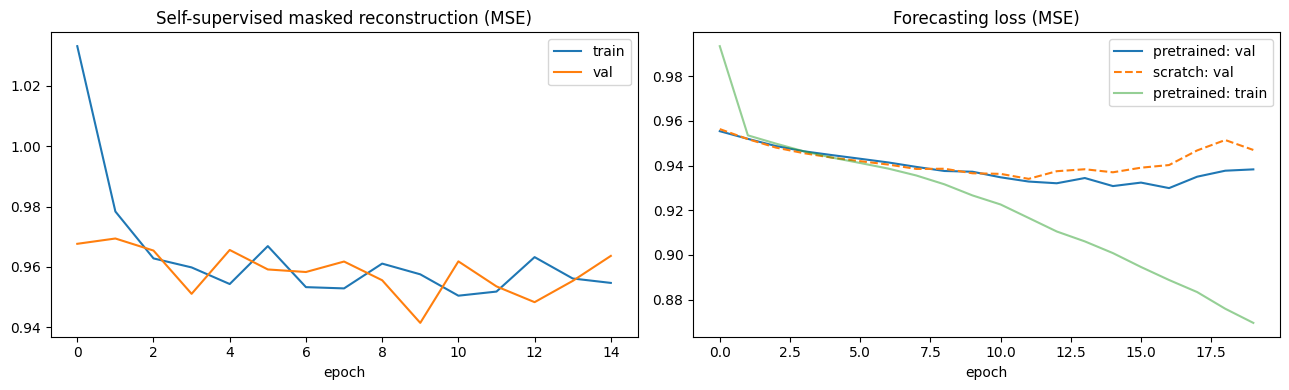

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(pre_hist["train"], label="train"); ax[0].plot(pre_hist["val"], label="val")
ax[0].set_title("Self-supervised masked reconstruction (MSE)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ft_hist["val"], label="pretrained: val"); ax[1].plot(scratch_hist["val"], label="scratch: val", linestyle="--")
ax[1].plot(ft_hist["train"], label="pretrained: train", alpha=0.5)
ax[1].set_title("Forecasting loss (MSE)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

In [15]:
from sklearn.linear_model import Ridge

def lag_feats(x, p):                      # last p time steps, flattened
    return x[:, -p:, :].reshape(len(x), -1).numpy()

def fit_ridge(p, alpha):
    tr = data["train"]
    return Ridge(alpha=alpha).fit(lag_feats(tr[:, :cfg.ctx], p),
                                  tr[:, cfg.ctx:].reshape(len(tr), -1).numpy())

def ridge_predict(m, name, p):
    x = data[name][:, :cfg.ctx]
    out = m.predict(lag_feats(x, p))
    return torch.tensor(out, dtype=torch.float32).view(-1, cfg.horizon, cfg.n_regions)

# choose p and alpha on VALIDATION only
yv = data["val"][:, cfg.ctx:]
rows = []
for p in [1, 2, 4, 8]:
    for alpha in [10, 100, 1000, 1e4, 1e5]:
        pv = ridge_predict(fit_ridge(p, alpha), "val", p)
        rows.append((p, alpha, ((pv - yv) ** 2).mean().item()))
grid = pd.DataFrame(rows, columns=["p", "alpha", "val_mse"]).sort_values("val_mse")
print(grid.head(5).to_string(index=False))

best_p, best_alpha = int(grid.iloc[0].p), float(grid.iloc[0].alpha)
ridge_best = fit_ridge(best_p, best_alpha)

# per-step validation R2 of the chosen ridge
pv = ridge_predict(ridge_best, "val", best_p)
e = (pv - yv).numpy()
sst = ((yv.numpy() - yv.numpy().mean()) ** 2).mean(axis=(0, 2))
print("horizon in current data:", cfg.horizon)
print("ridge val R2 per step:", np.round(1 - (e ** 2).mean(axis=(0, 2)) / sst, 3))

 p   alpha  val_mse
 8 10000.0 0.903566
 4 10000.0 0.911968
 1  1000.0 0.915167
 2  1000.0 0.917845
 4  1000.0 0.919548
horizon in current data: 10
ridge val R2 per step: [0.129 0.056 0.045 0.031 0.035 0.035 0.03  0.033 0.038 0.021]


## Cell 11 - Evaluation on held-out test subjects
**What this cell does:** computes MAE, RMSE and R2 on held-out test subjects and compares against simple baselines: persistence, context mean, a zero (training mean) predictor, and a group-average time-course predictor built from training subjects. A model is only useful if it beats these. Test results are used only for final reporting, never for choosing settings.

In [16]:
@torch.no_grad()
def predict(m, x, bs=256):
    m.eval(); out = []
    for i in range(0, len(x), bs):
        out.append(m.forecast(x[i:i + bs].to(device)).cpu())
    return torch.cat(out)

def metrics(pred, true):
    err = (pred - true).numpy().ravel(); t = true.numpy().ravel()
    mae = np.abs(err).mean(); rmse = math.sqrt((err ** 2).mean())
    r2 = 1 - (err ** 2).sum() / ((t - t.mean()) ** 2).sum()
    return {"MAE": mae, "RMSE": rmse, "R2": r2}

xt, yt = data["test"][:, :cfg.ctx], data["test"][:, cfg.ctx:]
preds = {
    "NeuroTwin (pretrained)": predict(model, xt),
    "Transformer (no pretraining)": predict(scratch, xt),
    "Baseline: persistence": xt[:, -1:, :].repeat(1, cfg.horizon, 1),
    "Baseline: context mean": xt.mean(1, keepdim=True).repeat(1, cfg.horizon, 1),
}
L = cfg.ctx + cfg.horizon
n_win = (cfg.T - L) // cfg.stride + 1
group_mean = clean[split['train']].mean(0)                       # (T, R), training subjects only
starts = np.array([(i % n_win) * cfg.stride for i in range(len(xt))])
g_pred = torch.tensor(np.stack([group_mean[s + cfg.ctx: s + cfg.ctx + cfg.horizon] for s in starts]))

preds["Baseline: zero (train mean)"] = torch.zeros_like(yt)
preds["Baseline: group-avg time course"] = g_pred
preds["Baseline: ridge (lag-VAR)"] = ridge_predict(ridge_best, "test", best_p)
results = pd.DataFrame({k: metrics(v, yt) for k, v in preds.items()}).T.round(4)
display(results) if "display" in globals() else print(results)

                                    MAE    RMSE      R2
NeuroTwin (pretrained)           0.7667  0.9701  0.0137
Transformer (no pretraining)     0.7676  0.9710  0.0119
Baseline: persistence            1.0432  1.3240 -0.8374
Baseline: context mean           0.8012  1.0110 -0.0713
Baseline: zero (train mean)      0.7730  0.9768 -0.0000
Baseline: group-avg time course  0.7451  0.9454  0.0632
Baseline: ridge (lag-VAR)        0.7547  0.9556  0.0429


In [17]:
xv, yv = data["val"][:, :cfg.ctx], data["val"][:, cfg.ctx:]
ev = (predict(model, xv) - yv).numpy()
sst = ((yv.numpy() - yv.numpy().mean()) ** 2).mean(axis=(0, 2))
print(np.round(1 - (ev ** 2).mean(axis=(0, 2)) / sst, 3))

[ 0.076  0.025  0.02  -0.007  0.004  0.003 -0.     0.013  0.024  0.018]


## Cell 12 - Actual vs predicted signals
**What this cell does:** picks a few test windows and plots the input context, the true future signal and the model's predicted future for selected regions.

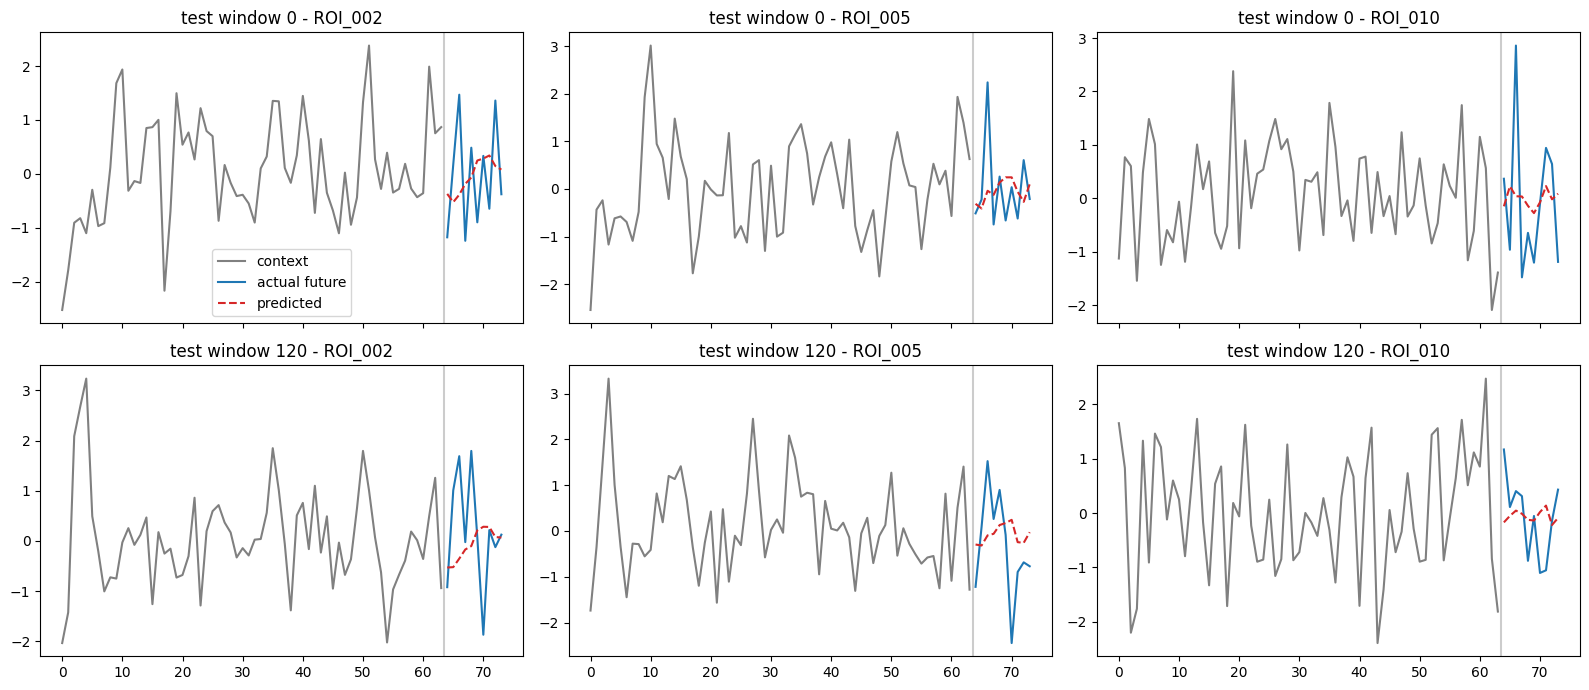

In [18]:
pred_best = preds["NeuroTwin (pretrained)"]
regions_to_show, windows_to_show = [2, 5, 10], [0, len(xt) // 2]
fig, axes = plt.subplots(len(windows_to_show), len(regions_to_show), figsize=(16, 7), sharex=True)
tc = np.arange(cfg.ctx); tf = np.arange(cfg.ctx, cfg.ctx + cfg.horizon)
for r_i, w in enumerate(windows_to_show):
    for c_i, reg in enumerate(regions_to_show):
        a = axes[r_i, c_i]
        a.plot(tc, xt[w, :, reg], color="gray", label="context")
        a.plot(tf, yt[w, :, reg], color="tab:blue", label="actual future")
        a.plot(tf, pred_best[w, :, reg], color="tab:red", linestyle="--", label="predicted")
        a.axvline(cfg.ctx - 0.5, color="k", alpha=0.2)
        a.set_title(f"test window {w} - {roi_names[reg]}")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## Cell 13 - Per-region error and prediction horizon analysis
**What this cell does:** shows where the model is strong or weak: RMSE for each brain region, and how error grows as we predict further into the future.

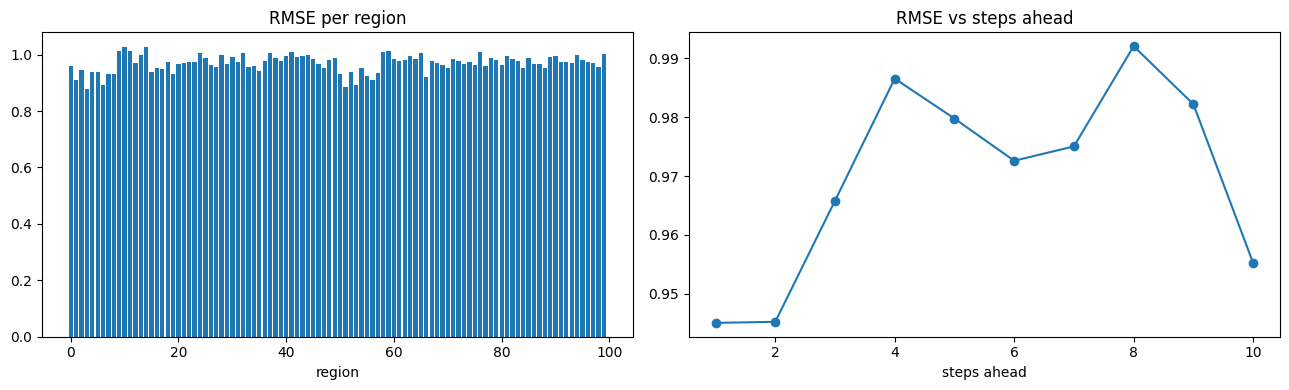

In [19]:
err = (pred_best - yt).numpy()
rmse_region = np.sqrt((err ** 2).mean(axis=(0, 1)))
rmse_step = np.sqrt((err ** 2).mean(axis=(0, 2)))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(R), rmse_region); ax[0].set_title("RMSE per region"); ax[0].set_xlabel("region")
ax[1].plot(range(1, cfg.horizon + 1), rmse_step, marker="o"); ax[1].set_title("RMSE vs steps ahead"); ax[1].set_xlabel("steps ahead")
plt.tight_layout(); plt.show()

## Cell 14 - Learned brain embeddings
**What this cell does:** extracts the encoder's representation of each test window, reduces it to 2D with PCA, and colours points by child/adult group. This is a descriptive plot only; no claims about development or any condition are made from it.

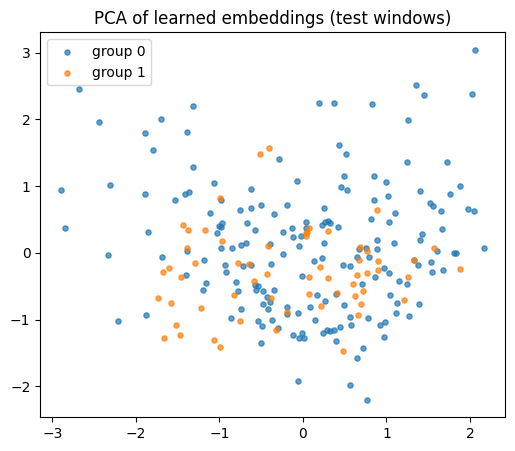

In [20]:
@torch.no_grad()
def embed(m, x, bs=256):
    m.eval(); out = []
    for i in range(0, len(x), bs):
        out.append(m.encode(x[i:i + bs].to(device)).mean(1).cpu())
    return torch.cat(out).numpy()

emb = embed(model, xt)
emb2 = PCA(n_components=2, random_state=SEED).fit_transform(emb)
g = groups[win_subj["test"]]
plt.figure(figsize=(6, 5))
for gi, col in [(0, "tab:blue"), (1, "tab:orange")]:
    plt.scatter(emb2[g == gi, 0], emb2[g == gi, 1], s=14, alpha=0.7, c=col, label=f"group {gi}")
plt.title("PCA of learned embeddings (test windows)"); plt.legend(); plt.show()

## Cell 15 - Uncertainty with Monte-Carlo dropout
**What this cell does:** keeps dropout active at inference and runs the model 30 times to get a mean prediction and a standard deviation (an uncertainty band). It then checks how often the true signal falls inside the +/-2 std band (a simple calibration check).

Fraction of true values inside +/-2 std band: 5.91%  (well-calibrated ~95%)


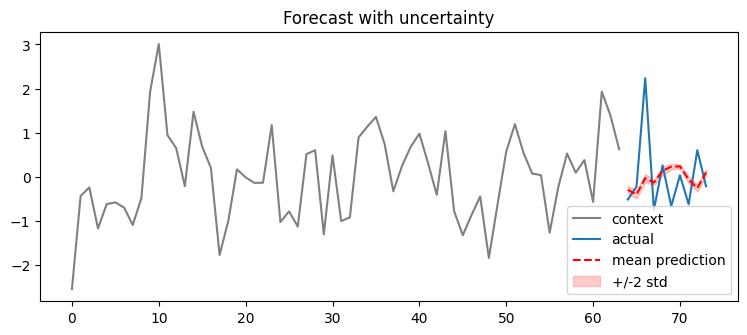

In [31]:
@torch.no_grad()
def mc_predict(m, x, n=30):
    m.train()                                     # dropout ON
    outs = torch.stack([m.forecast(x.to(device)).cpu() for _ in range(n)])
    m.eval()
    return outs.mean(0), outs.std(0)

mu, sd = mc_predict(model, xt[:200])
inside = ((yt[:200] >= mu - 2 * sd) & (yt[:200] <= mu + 2 * sd)).float().mean().item()
print(f"Fraction of true values inside +/-2 std band: {inside:.2%}  (well-calibrated ~95%)")

w, reg = 0, 5
plt.figure(figsize=(9, 3.5))
plt.plot(tc, xt[w, :, reg], color="gray", label="context")
plt.plot(tf, yt[w, :, reg], label="actual")
plt.plot(tf, mu[w, :, reg], "r--", label="mean prediction")
plt.fill_between(tf, (mu - 2 * sd)[w, :, reg], (mu + 2 * sd)[w, :, reg], color="r", alpha=0.2, label="+/-2 std")
plt.title("Forecast with uncertainty"); plt.legend(); plt.show()

## Cell 16 - Export the trained model
**What this cell does:** saves the model weights together with the config into a single `.pt` file and writes the metrics to JSON, so the model can be reloaded later or downloaded from Colab.

In [22]:
ckpt_path = "neurotwin_colab.pt"
torch.save({"state_dict": model.state_dict(), "cfg": asdict(cfg)}, ckpt_path)
results.to_json("neurotwin_metrics.json", indent=2)
print("Saved:", ckpt_path, f"({os.path.getsize(ckpt_path)/1e3:.0f} KB) and neurotwin_metrics.json")

try:
    from google.colab import files
    files.download(ckpt_path)                    # triggers a browser download when running in Colab
except Exception as e:
    print("Not running in Colab (or download blocked):", type(e).__name__)

Saved: neurotwin_colab.pt (759 KB) and neurotwin_metrics.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Cell 17 - Inference on new data
**What this cell does:** reloads the saved checkpoint into a fresh model and defines `forecast_brain(signal)`, which takes raw parcellated array of shape (time, 100 regions), preprocesses it the same way as training, and returns the next predicted steps (in z-scored units). It also verifies the reloaded model matches the original.

Forecast shape: (10, 100) | reload matches original: True


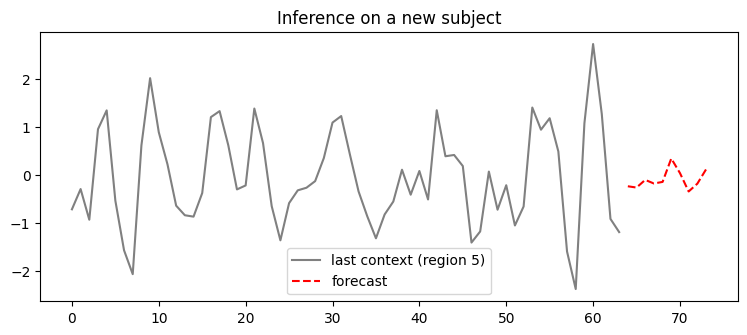

In [23]:
def load_model(path):
    ck = torch.load(path, map_location=device)
    c = Cfg(**ck["cfg"]); m = BrainEncoder(c).to(device)
    m.load_state_dict(ck["state_dict"]); m.eval()
    return m, c

def forecast_brain(signal, m, c):
    """signal: np.ndarray (time >= ctx, n_regions) raw values. Returns (horizon, n_regions) z-scored forecast."""
    x = preprocess(np.asarray(signal, dtype=np.float32))[-c.ctx:]
    with torch.no_grad():
        return m.forecast(torch.tensor(x).unsqueeze(0).to(device)).cpu().numpy()[0]

loaded, loaded_cfg = load_model(ckpt_path)
new_subject = raw[split["test"][0]]     # a real held-out subject (raw, unprocessed)
fc = forecast_brain(new_subject, loaded, loaded_cfg)
same = forecast_brain(new_subject, model.eval(), cfg)
print("Forecast shape:", fc.shape, "| reload matches original:", np.allclose(fc, same, atol=1e-5))

plt.figure(figsize=(9, 3.5))
ctx_sig = preprocess(new_subject)[-cfg.ctx:, 5]
plt.plot(range(cfg.ctx), ctx_sig, color="gray", label="last context (region 5)")
plt.plot(range(cfg.ctx, cfg.ctx + cfg.horizon), fc[:, 5], "r--", label="forecast")
plt.title("Inference on a new subject"); plt.legend(); plt.show()

In [35]:
import contextlib, io, time

os.makedirs(f'{PROJ}/results', exist_ok=True)
RES_PATH = f'{PROJ}/results/runs.csv'
FRACS = [0.1, 0.25, 0.5, 1.0]
SEEDS = [0, 1, 2, 3, 4]
L = cfg.ctx + cfg.horizon
n_win = (cfg.T - L) // cfg.stride + 1
full_train = data["train"]
xt_, yt_ = data["test"][:, :cfg.ctx], data["test"][:, cfg.ctx:]
test_rows = win_subj["test"]
pid = pk["participant_id"].values

def steps_to_epochs(n_windows, base_steps, min_epochs):
    return max(min_epochs, math.ceil(base_steps / math.ceil(n_windows / cfg.batch)))

def per_subject_mse(pred):
    w = ((pred - yt_) ** 2).mean(dim=(1, 2)).numpy()
    return pd.Series(w).groupby(test_rows).mean()

def run_one(seed, frac):
    rows = np.array([row_of[s] for s in splits["subsets"][str(seed)][str(frac)]])
    data["train"] = make_windows(rows)[0]
    n = len(data["train"])
    pre_ep = steps_to_epochs(n, 225, cfg.pre_epochs)
    ft_ep = steps_to_epochs(n, 300, cfg.ft_epochs)
    with contextlib.redirect_stdout(io.StringIO()):
        torch.manual_seed(seed); m_s = BrainEncoder(cfg).to(device)
        finetune(m_s, ft_ep, tag="scratch")
        torch.manual_seed(seed); m_p = BrainEncoder(cfg).to(device)
        pretrain(m_p, pre_ep)
        finetune(m_p, ft_ep, tag="pretrained")
    gm = clean[rows].mean(0)
    starts = np.array([(i % n_win) * cfg.stride for i in range(len(xt_))])
    g_pred = torch.tensor(np.stack([gm[s + cfg.ctx: s + cfg.ctx + cfg.horizon] for s in starts]))
    preds_ = {
        "scratch": predict(m_s, xt_),
        "pretrained": predict(m_p, xt_),
        "ridge": ridge_predict(fit_ridge(best_p, best_alpha), "test", best_p),
        "group_avg": g_pred,
        "zero": torch.zeros_like(yt_),
    }
    out = []
    for arm, pr in preds_.items():
        for r, v in per_subject_mse(pr).items():
            out.append(dict(seed=seed, frac=frac, n_train=len(rows), arm=arm, subject=pid[r], mse=v))
    return pd.DataFrame(out)

done = set()
if os.path.exists(RES_PATH):
    prev = pd.read_csv(RES_PATH)
    done = set(zip(prev.seed, prev.frac))

t0 = time.time()
for seed in SEEDS:
    for frac in FRACS:
        if (seed, frac) in done:
            continue
        df_ = run_one(seed, frac)
        df_.to_csv(RES_PATH, mode="a", header=not os.path.exists(RES_PATH), index=False)
        print(f"seed {seed} frac {frac} done | {time.time() - t0:.0f}s elapsed")
data["train"] = full_train
d = pd.read_csv(RES_PATH)
print("rows:", len(d), "| runs:", d.groupby(["seed", "frac"]).ngroups)
print(d.groupby("frac")["n_train"].first())

rows: 2000 | runs: 20
frac
0.10     8
0.25    19
0.50    38
1.00    76
Name: n_train, dtype: int64


In [25]:
df = pd.read_csv(RES_PATH)
print("runs per (seed, frac):", df.groupby(["seed", "frac"]).ngroups, "| rows:", len(df))

piv = df.pivot_table(index=["frac", "subject"], columns="arm", values="mse", aggfunc="mean")  # mean over seeds
piv["diff"] = piv["scratch"] - piv["pretrained"]          # positive = pretraining helps
rng = np.random.default_rng(0)
print("\nfrac | mean diff | 95% bootstrap CI over subjects")
for frac, g in piv.groupby(level="frac"):
    d = g["diff"].values
    boots = [rng.choice(d, len(d)).mean() for _ in range(5000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    print(f"{frac:4} | {d.mean():+.4f} | [{lo:+.4f}, {hi:+.4f}]")

print()
print(piv.groupby(level="frac")[["scratch", "pretrained", "ridge", "group_avg", "zero"]].mean().round(4))

runs per (seed, frac): 20 | rows: 2000

frac | mean diff | 95% bootstrap CI over subjects
 0.1 | +0.0020 | [+0.0017, +0.0024]
0.25 | +0.0029 | [+0.0021, +0.0037]
 0.5 | +0.0005 | [-0.0021, +0.0030]
 1.0 | +0.0031 | [+0.0012, +0.0049]

arm   scratch  pretrained   ridge  group_avg    zero
frac                                                
0.10   0.9649      0.9628  0.9470     0.9906  0.9541
0.25   0.9593      0.9564  0.9357     0.9288  0.9541
0.50   0.9519      0.9514  0.9257     0.9061  0.9541
1.00   0.9446      0.9415  0.9131     0.8939  0.9541


# Cell: Per-seed consistency check

In [26]:
d = df[df.arm.isin(["scratch", "pretrained"])].pivot_table(index=["seed", "frac", "subject"], columns="arm", values="mse")
d["diff"] = d["scratch"] - d["pretrained"]
print(d.groupby(["frac", "seed"])["diff"].mean().unstack("seed").round(4))

seed       0       1       2       3       4
frac                                        
0.10  0.0020  0.0033  0.0024  0.0009  0.0017
0.25  0.0024  0.0026  0.0036  0.0025  0.0034
0.50  0.0036  0.0037  0.0020 -0.0049 -0.0018
1.00  0.0048  0.0028  0.0043  0.0005  0.0030


# Cell: The data-scaling plot

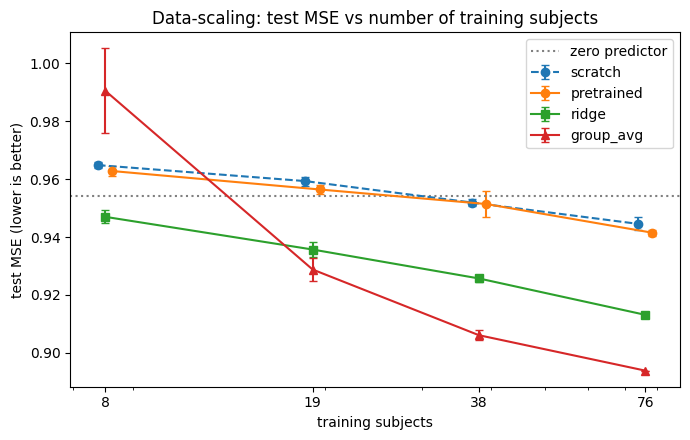

In [29]:
from matplotlib.ticker import ScalarFormatter, NullFormatter
import pandas as pd
import os

# Ensure PROJ is defined
if 'PROJ' not in globals():
    PROJ = '/content/drive/MyDrive/neurotwin'

# Ensure df is defined: check globals first, then fallback to CSV
if 'df' not in globals() or df is None:
    RES_PATH = f'{PROJ}/results/runs.csv'
    if os.path.exists(RES_PATH):
        df = pd.read_csv(RES_PATH)
    else:
        raise FileNotFoundError(f"Results file not found at {RES_PATH}. Please run the experiments first.")

g = df.groupby(["frac", "seed", "arm"])["mse"].mean().reset_index()
n_of = df.groupby("frac")["n_train"].first()
fig, ax = plt.subplots(figsize=(7, 4.5))
for arm, style in [("scratch", "o--"), ("pretrained", "o-"), ("ridge", "s-"), ("group_avg", "^-")]:
    s = g[g.arm == arm].groupby("frac")["mse"].agg(["mean", "std"])
    shift = {"scratch": 0.97, "pretrained": 1.03}.get(arm, 1.0)
    ax.errorbar(n_of.loc[s.index] * shift, s["mean"], yerr=s["std"], fmt=style, capsize=3, label=arm)
ax.axhline(g[g.arm == "zero"]["mse"].mean(), color="gray", linestyle=":", label="zero predictor")
ax.set_xscale("log")
ax.set_xticks([8, 19, 38, 76])
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel("training subjects")
ax.set_ylabel("test MSE (lower is better)")
ax.set_title("Data-scaling: test MSE vs number of training subjects")
ax.legend()
plt.tight_layout()
if os.path.exists(f'{PROJ}/results'):
    plt.savefig(f'{PROJ}/results/scaling_plot.png', dpi=150)
else:
    plt.savefig('scaling_plot.png', dpi=150)
plt.show()

# Cell: conformal calibration

In [32]:
ALPHA = 0.05                                    # target coverage 95%
xc, yc = data["cal"][:, :cfg.ctx], data["cal"][:, cfg.ctx:]
g_test = groups[win_subj["test"]]               # 0 = child, 1 = adult

def conformal_eval(pred_cal, pred_test, name):
    s = (pred_cal - yc).abs().numpy()                       # (cal windows, horizon, regions)
    n = s.shape[0] * s.shape[2]
    level = min(1.0, np.ceil((n + 1) * (1 - ALPHA)) / n)
    q = np.array([np.quantile(s[:, k, :].ravel(), level) for k in range(cfg.horizon)])  # one width per step
    qt = torch.tensor(q, dtype=torch.float32).view(1, -1, 1)
    inside = ((yt >= pred_test - qt) & (yt <= pred_test + qt)).float()
    cov_subj = pd.Series(inside.mean(dim=(1, 2)).numpy()).groupby(win_subj["test"]).mean()
    cov_grp = pd.Series(inside.mean(dim=(1, 2)).numpy()).groupby(g_test).mean()
    print(f"{name}: coverage {inside.mean().item():.1%} | mean interval width {2 * q.mean():.3f}")
    print(f"   per-subject coverage: min {cov_subj.min():.1%}, median {cov_subj.median():.1%}, max {cov_subj.max():.1%}")
    print(f"   children {cov_grp.get(0, float('nan')):.1%} | adults {cov_grp.get(1, float('nan')):.1%}")
    return q
conformal_eval(torch.zeros_like(yc), torch.zeros_like(yt), "Zero predictor (no model)")
q_tf = conformal_eval(predict(model, xc), predict(model, xt), "Transformer (pretrained)")
q_rg = conformal_eval(ridge_predict(ridge_best, "cal", best_p), ridge_predict(ridge_best, "test", best_p), "Ridge")

Zero predictor (no model): coverage 94.6% | mean interval width 3.770
   per-subject coverage: min 93.3%, median 94.4%, max 95.9%
   children 94.7% | adults 94.2%
Transformer (pretrained): coverage 94.3% | mean interval width 3.711
   per-subject coverage: min 92.8%, median 94.3%, max 95.9%
   children 94.4% | adults 94.1%
Ridge: coverage 94.4% | mean interval width 3.669
   per-subject coverage: min 92.5%, median 94.4%, max 96.1%
   children 94.5% | adults 94.1%


In [36]:
x = clean[split['train']]
print("mean lag-1 autocorrelation:", np.mean([np.corrcoef(s[:-1, r], s[1:, r])[0, 1] for s in x for r in range(R)]))

mean lag-1 autocorrelation: 0.4138612173789571


## Limitations
- Small public dataset (128 subjects, 168 time points each); one task (watching a short animated film); results may not generalise to other data or scale.
- Children and adults are mixed (96 and 32 after exclusion); the test set has only 5 adults, so no group-specific claims are made.
- All subjects watch the same movie, so signals are partly time-locked across subjects; a group-average baseline checks for this.
- Subjects above 0.5 mm mean head motion were excluded (more children than adults), so the retained children are calmer than the full sample.
- fMRI forecasting is a low-signal task; absolute performance is modest.
- Per-subject normalisation uses the full scan (mild look-ahead).
- A single-seed pilot was inspected before the final design was fixed; final choices were made on validation data.
- MC-dropout intervals are poorly calibrated; conformal prediction is used to fix this.
- This is a learning project: no diagnosis, no treatment advice, not a medical device.